
# 02425 Diffusion and stochastich differential equations


## WEEK 7: Existence and uniqueness, numerics, and Stratonovich SDE

### Conditions for existence and uniqueness

In [1]:
import numpy as np
import random
from numpy import random
from matplotlib import pyplot as plt
import scipy.stats as stats

### Exercise 1

The first one has an f and a g function which both af globally lipshitz. Note also that the f and g fucntions satifsfies the inequalities in theorem 8.3.1. Therfore there exist a unique ito process that satisfies the ito equation.

The second one the f and g functions a locally and globaly lipshitz respectively. But f can not be bounded with respect to theroem 8.3.1. Therefore the process will for some finite value of T, explode.

The third one has the same properties as the second, but its f function can be bounded by theorem 8.3.1. Therefore it has a unique ito process that satifies the ito equation.

The fourth one satisfies global lipshitz conitnuity for the f fucntion and local lipshtiz continuity for the g function, as long as the process hasnt hit the origin. Therffore there exist only a solution upto when the process hits the origin.

### The physical pendulum

### Exercise 2

We are working with a narrow sence linear sde. It is also clear here that the ito and stratonovich solution are identical, since the differ by $⟨G,B⟩_t / 2$. Since the cross variation between these two are 0 (since G does not depend on $B_t$) we conclude that the ito and stratonovich solutions are identical.

Existence and uniqueness comes from that the system can be bounded by a two dimensional coupled linear narrow sense sde. Here it can be shown that both f and g (trivial) er globally lipshitz (for the upper bound system). and they both satisfies the conditions in theorem 8.3.1.

### Exercise 3

In [2]:
def Brownian(partition):

    BrownianMotion = np.array([])

    for i in range(len(partition)):

        if partition[i] == 0:
            BrownianMotion = np.append(BrownianMotion, 0)
        if partition[i] != 0:
            BrownianMotion = np.append(BrownianMotion, random.normal(loc=BrownianMotion[-1], scale=np.sqrt(partition[i]-partition[i-1])))

    return BrownianMotion



In [3]:
lmda = 0.1


gamma = 1
chsi = 2

T = 1000
dt = 0.01
x = chsi



f = lambda x: lmda * (chsi - x)
g = lambda x: gamma*np.sqrt(np.abs(x))




sigma = 0.01
x = 0
v = 0

partition = np.linspace(0, T, int(T/dt))

Bt = Brownian(partition)

def eulersumL(f,g,T,dt,x):
    N = int(T/dt)
    t = np.linspace(0, T, N)
    X = np.zeros(N)
    V = np.zeros(N)
    X[0] = x
    V[0] = v



    for i in range(1, N):

        X[i] = V[i-1]
        V[i] = np.sin(X[i-1]) + sigma * (Bt[i] - Bt[i-1])

    return t, X, V

t, XL, VL = eulersumL(f, g, T, dt, x)

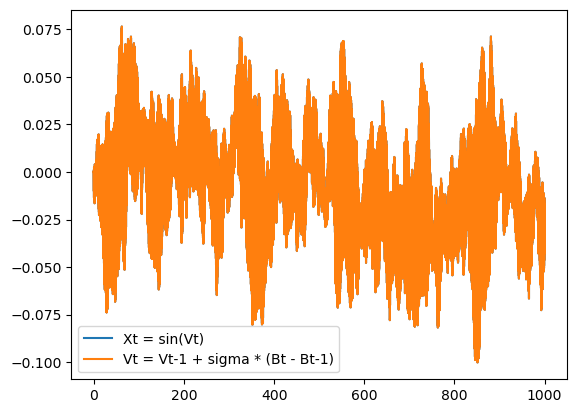

In [4]:
plt.plot(t, XL, label="Xt = sin(Vt)")
plt.plot(t, VL, label="Vt = Vt-1 + sigma * (Bt - Bt-1)")
plt.legend()

sigma = 0.01
Mean = 3.141666851779683
Variance = 0.000476188853137772

sigma = 0.1
Mean = 3.1425810082285492
Variance = 0.051528238701594835

sigma = 1
Mean = -1.7072658935833482
Variance = 681.6891749720198

sigma = 1.4142135623730951
Mean = 190.64385000881887
Variance = 7229.18737472622



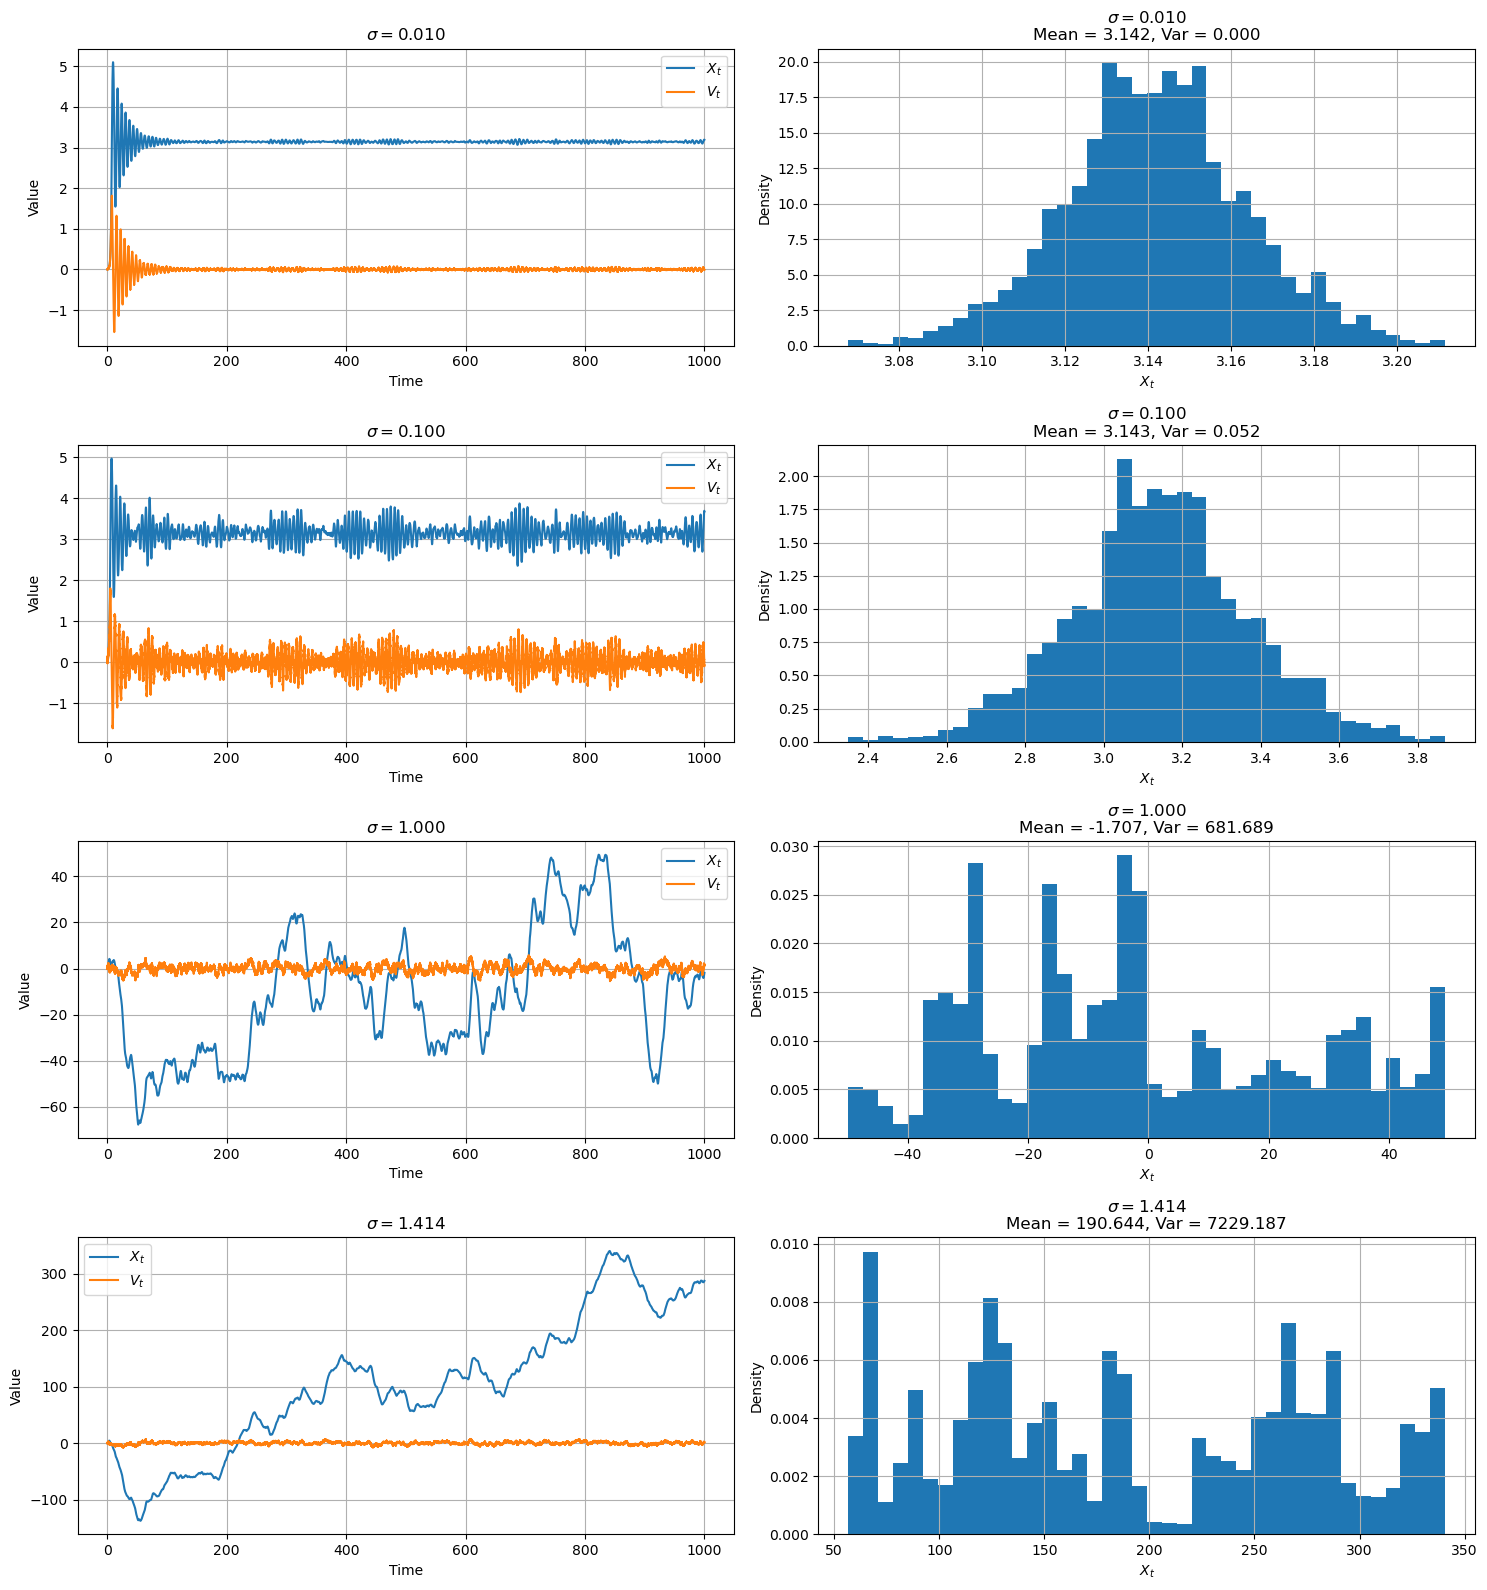

In [9]:
import numpy as np
import matplotlib.pyplot as plt

lmda = 0.1

T = 1000
dt = 0.01
x = 0
v = 0

sigmas = [0.01, 0.1, 1, np.sqrt(2)]

partition = np.linspace(0, T, int(T/dt) + 1)

Bt = Brownian(partition)


def eulersumL(f, g, T, dt, x):
    N = int(T/dt)
    t = np.linspace(0, T, N + 1)

    X = np.zeros(N + 1)
    V = np.zeros(N + 1)
    X[0] = x
    V[0] = v

    for i in range(1, N + 1):

        X[i] = X[i-1] + V[i-1] * dt

        V[i] = V[i-1] + f(X[i-1], V[i-1]) * dt + g(X[i-1]) * (Bt[i] - Bt[i-1])

    return t, X, V


fig, axs = plt.subplots(4, 2, figsize=(15, 16))

for i, sigma in enumerate(sigmas):

    f = lambda x, v: np.sin(x) - lmda * v
    g = lambda x: sigma

    t, XL, VL = eulersumL(f, g, T, dt, x)

    XL_stationary = XL[len(XL)//2:]

    mean = np.mean(XL_stationary)
    variance = np.var(XL_stationary)

    # Plot solutions
    axs[i, 0].plot(t, XL, label=r"$X_t$")
    axs[i, 0].plot(t, VL, label=r"$V_t$")
    axs[i, 0].set_title(rf"$\sigma={sigma:.3f}$")
    axs[i, 0].set_xlabel("Time")
    axs[i, 0].set_ylabel("Value")
    axs[i, 0].legend()
    axs[i, 0].grid()

    # Histogram
    axs[i, 1].hist(XL_stationary, bins=40, density=True)

    axs[i, 1].set_title(
        rf"$\sigma={sigma:.3f}$" + "\n" +
        rf"Mean = {mean:.3f}, Var = {variance:.3f}"
    )

    axs[i, 1].set_xlabel(r"$X_t$")
    axs[i, 1].set_ylabel("Density")
    axs[i, 1].grid()

    print("sigma =", sigma)
    print("Mean =", mean)
    print("Variance =", variance)
    print()

plt.tight_layout()
plt.show()

### Conversion between Itō and Stratonovich equation

### Exercise 4

We know that the stratonovich process differs from the ito process by the following term $⟨G,B⟩_t / 2$. Therefore the stratonovich process that shares the same solution as the given ito process is given as the following.





$$
dX_t = \lambda(\mu-X_t)\,dt
+\sigma\sqrt{X_t}\,dB_t.
$$

The equivalent Stratonovich SDE is given by

$$
dX_t =
\left(f(X_t)-\frac12 g(X_t)g'(X_t)\right)dt
+g(X_t)\circ dB_t.
$$

Since

$$
g(x)=\sigma\sqrt{x},
\qquad
g'(x)=\frac{\sigma}{2\sqrt{x}},
$$

we obtain

$$
\frac12 g(x)g'(x)
=\frac12\sigma\sqrt{x}
\frac{\sigma}{2\sqrt{x}}
=\frac{\sigma^2}{4}.
$$

Hence, the equivalent Stratonovich equation is

$$
dX_t =
\left(\lambda(\mu-X_t)-\frac{\sigma^2}{4}\right)dt
+\sigma\sqrt{X_t}\circ dB_t.
$$

### Exercise 5

sigma = 0.01
Mean = 0.999711958656632
Variance = 5.2874929487855325e-05

sigma = 0.1
Mean = 0.9972511494912072
Variance = 0.005203894812262707

sigma = 1
Mean = 0.9811631305596591
Variance = 0.4702339353120276

sigma = 1.4142135623730951
Mean = 0.980006283114708
Variance = 0.9150624945533116



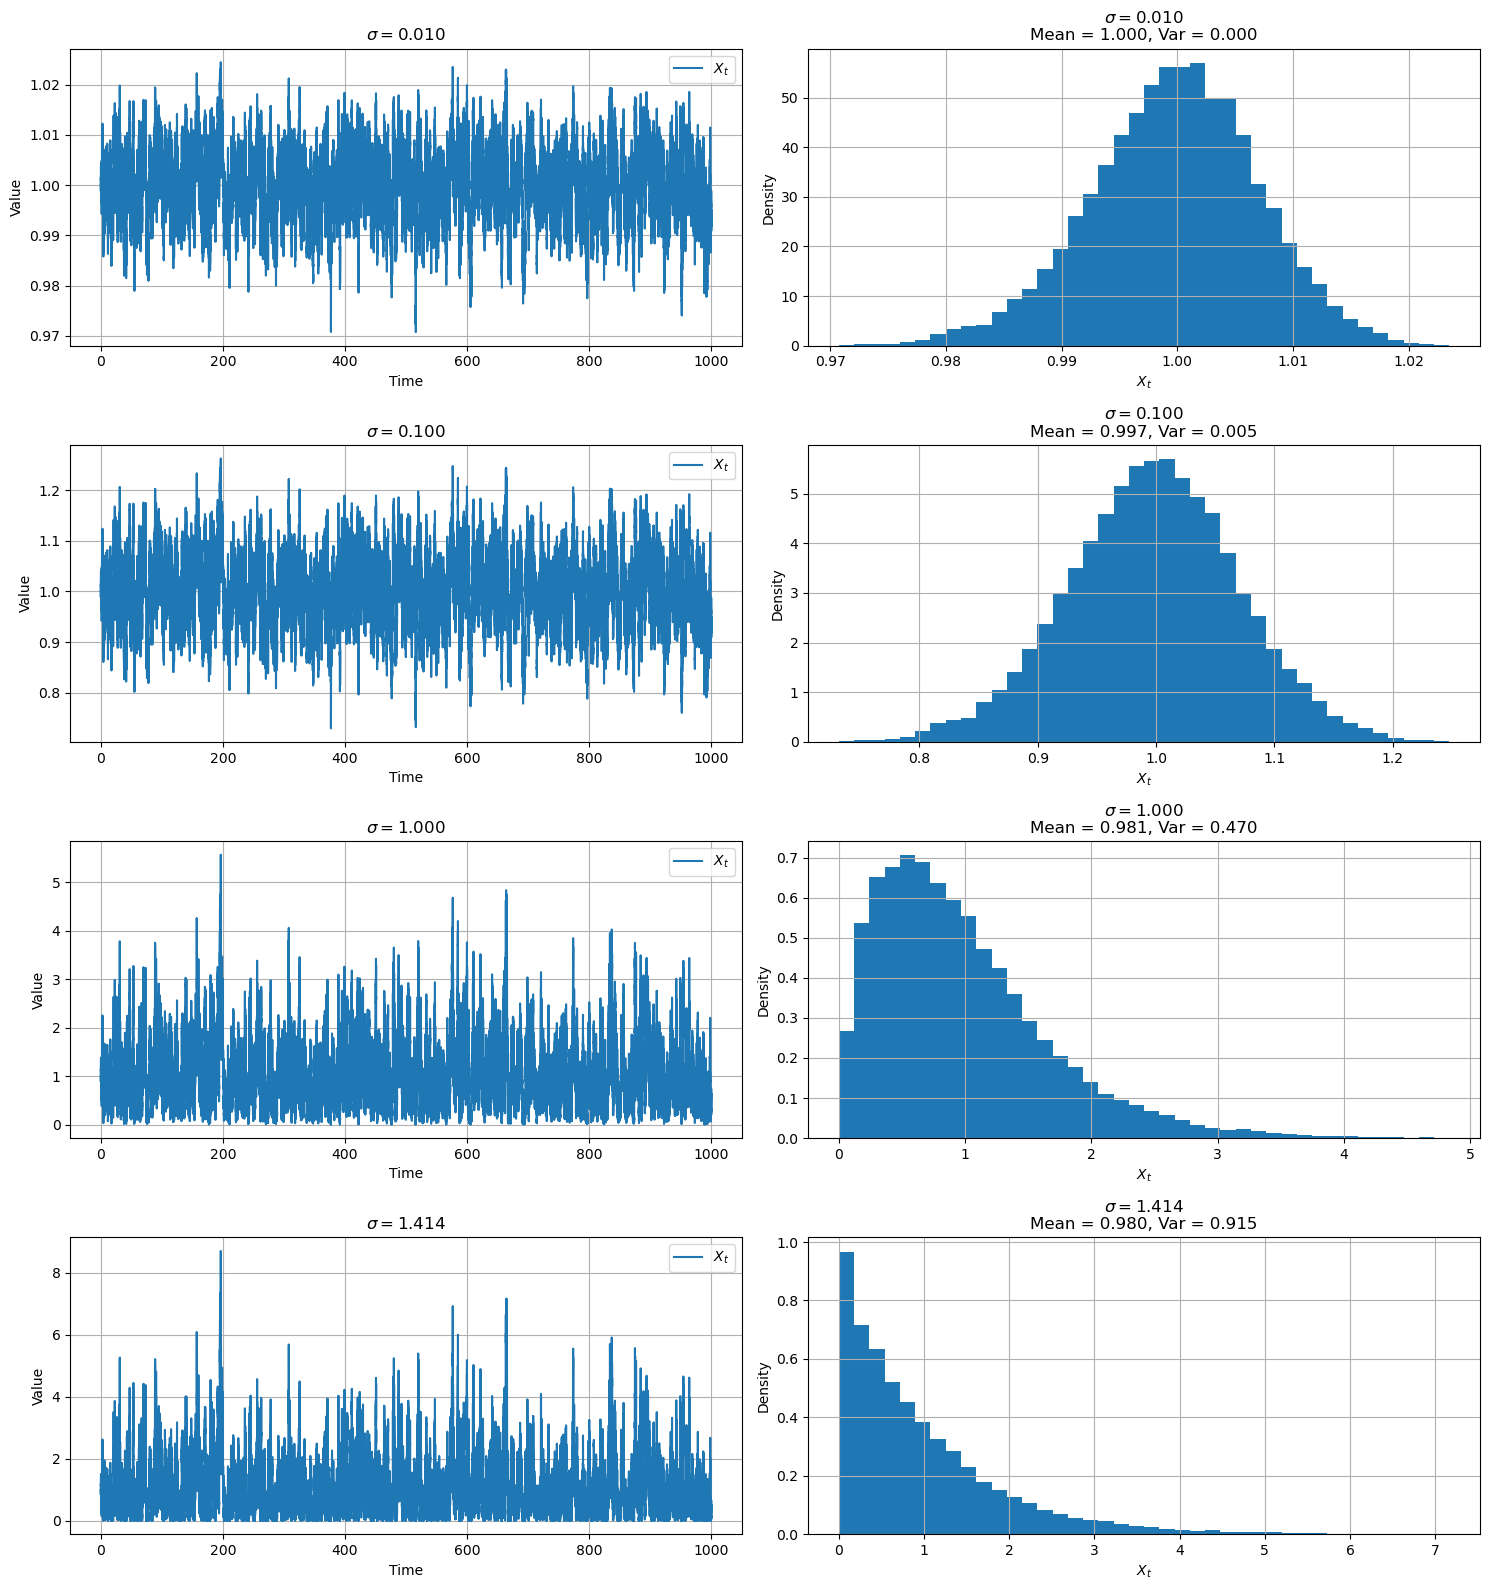

In [10]:

import numpy as np
import matplotlib.pyplot as plt

lmda = 1
mu = 1

T = 1000
dt = 0.01
x = 1

sigmas = [0.01, 0.1, 1, np.sqrt(2)]

partition = np.linspace(0, T, int(T/dt) + 1)

Bt = Brownian(partition)


def eulersumL(f, g, T, dt, x):
    N = int(T/dt)
    t = np.linspace(0, T, N + 1)

    X = np.zeros(N + 1)
    X[0] = x

    for i in range(1, N + 1):

        X[i] = X[i-1] + f(X[i-1]) * dt + g(X[i-1]) * (Bt[i] - Bt[i-1])

        X[i] = max(0, X[i])

    return t, X


fig, axs = plt.subplots(4, 2, figsize=(15, 16))

for i, sigma in enumerate(sigmas):

    f = lambda x: lmda * (mu - x)
    g = lambda x: sigma * np.sqrt(max(0, x))

    t, XL = eulersumL(f, g, T, dt, x)

    XL_stationary = XL[len(XL)//2:]

    mean = np.mean(XL_stationary)
    variance = np.var(XL_stationary)

    # Plot solution
    axs[i, 0].plot(t, XL, label=r"$X_t$")
    axs[i, 0].set_title(rf"$\sigma={sigma:.3f}$")
    axs[i, 0].set_xlabel("Time")
    axs[i, 0].set_ylabel("Value")
    axs[i, 0].legend()
    axs[i, 0].grid()

    # Histogram
    axs[i, 1].hist(XL_stationary, bins=40, density=True)

    axs[i, 1].set_title(
        rf"$\sigma={sigma:.3f}$" + "\n" +
        rf"Mean = {mean:.3f}, Var = {variance:.3f}"
    )

    axs[i, 1].set_xlabel(r"$X_t$")
    axs[i, 1].set_ylabel("Density")
    axs[i, 1].grid()

    print("sigma =", sigma)
    print("Mean =", mean)
    print("Variance =", variance)
    print()

plt.tight_layout()
plt.show()


### Exercise 6

dt = 0.01
Mean absolute difference = 0.03340168340633194
Maximum difference = 0.16890706191976657

dt = 0.1
Mean absolute difference = 0.12188770337282609
Maximum difference = 0.9683344500703668



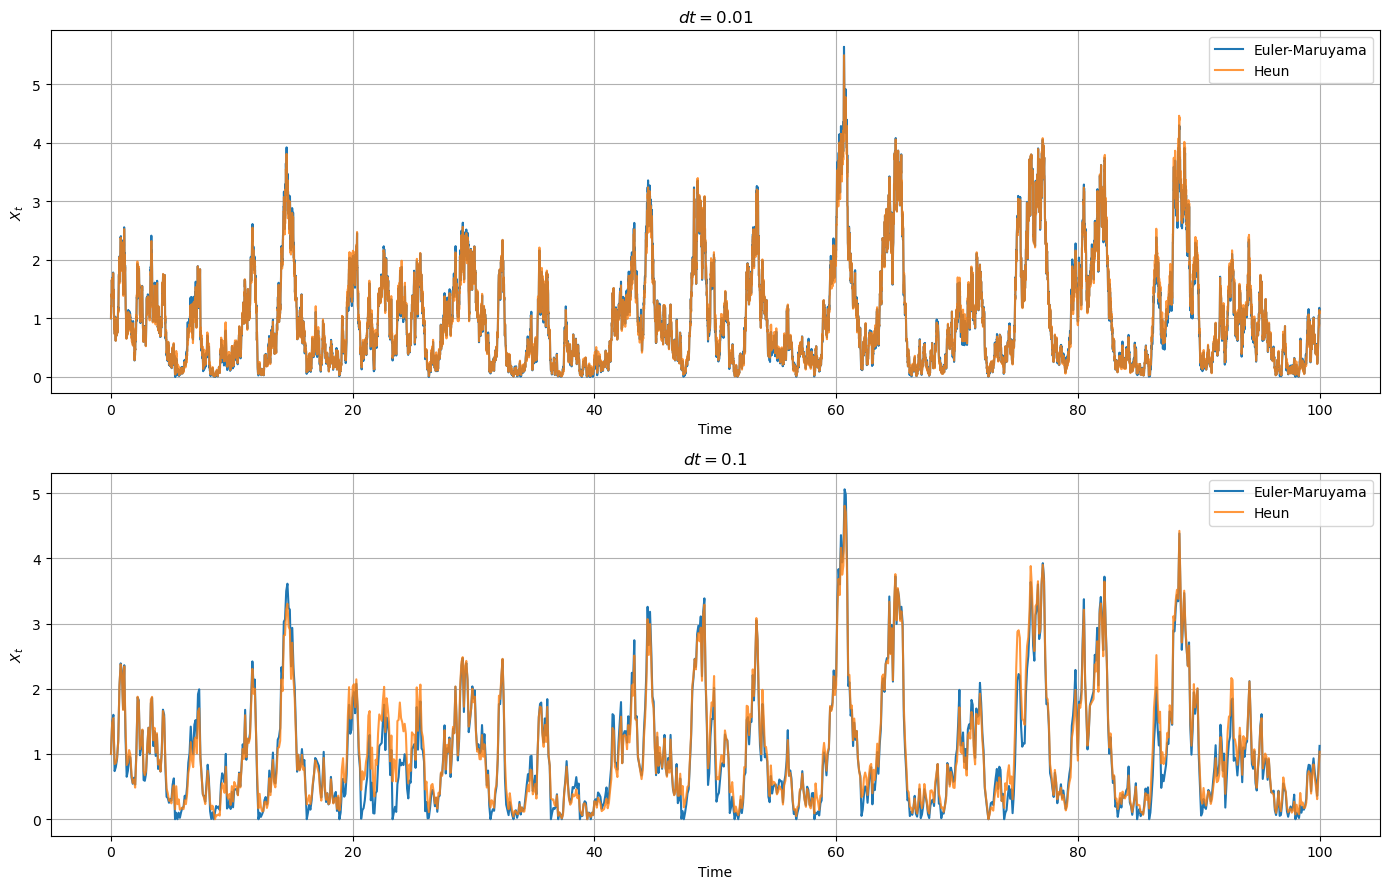

In [11]:

import numpy as np
import matplotlib.pyplot as plt

lmda = 1
mu = 1
sigma = 1.25

T = 100
dt = 0.01
x = 1

partition = np.linspace(0, T, int(T/dt) + 1)
Bt_fine = Brownian(partition)
Bt = Bt_fine.copy()


def eulersumL(f, g, T, dt, x):
    N = int(T/dt)
    t = np.linspace(0, T, N + 1)

    X = np.zeros(N + 1)
    X[0] = x

    for i in range(1, N + 1):

        X[i] = X[i-1] + f(X[i-1]) * dt + g(X[i-1]) * (Bt[i] - Bt[i-1])

        X[i] = max(0, X[i])

    return t, X


def heunsumL(f, g, T, dt, x):
    N = int(T/dt)
    t = np.linspace(0, T, N + 1)

    X = np.zeros(N + 1)
    X[0] = x

    for i in range(1, N + 1):

        dB = Bt[i] - Bt[i-1]

        Z = X[i-1] + f(X[i-1]) * dt + g(X[i-1]) * dB
        Z = max(0, Z)

        f_bar = 0.5 * (f(X[i-1]) + f(Z))
        g_bar = 0.5 * (g(X[i-1]) + g(Z))

        X[i] = X[i-1] + f_bar * dt + g_bar * dB

        X[i] = max(0, X[i])

    return t, X


f_ito = lambda x: lmda * (mu - x)
f_strat = lambda x: lmda * (mu - x) - sigma**2 / 4
g = lambda x: sigma * np.sqrt(max(0, x))


fig, axs = plt.subplots(2, 1, figsize=(14, 9))

for i, dt in enumerate([0.01, 0.1]):

    if dt == 0.01:
        Bt = Bt_fine.copy()
    else:
        Bt = Bt_fine[::10].copy()

    t, XL = eulersumL(f_ito, g, T, dt, x)
    t, XH = heunsumL(f_strat, g, T, dt, x)

    axs[i].plot(t, XL, label="Euler-Maruyama")
    axs[i].plot(t, XH, label="Heun", alpha=0.8)

    axs[i].set_title(rf"$dt={dt}$")
    axs[i].set_xlabel("Time")
    axs[i].set_ylabel(r"$X_t$")
    axs[i].legend()
    axs[i].grid()

    print("dt =", dt)
    print("Mean absolute difference =", np.mean(np.abs(XL - XH)))
    print("Maximum difference =", np.max(np.abs(XL - XH)))
    print()

plt.tight_layout()
plt.show()
